**MACHINE LEARNING 23CSE301 LAB ACTIVITY 12 — RANDOM FOREST CLASSIFIER**

**Exercise 1:** Consider the fruit basket as the data set, as shown in the figure. Now *n* samples are taken from the fruit basket, and an individual decision tree is constructed for each sample. Each decision tree will generate an output (Class-A = Apple, Class-B = Banana). Which fruit is likely to be taken most often?

**Approach:**
1. Build a fruit basket data set (Apple and Banana) with measurable features.
2. Draw *n* bootstrap samples (sampling with replacement) from the basket.
3. Train one decision tree on each sample (each split also considers only a random subset of features).
4. Let every tree predict the class of a new fruit (the *Instance*).
5. Apply **majority voting** to get the final class, which is the fruit taken most often.
6. Compare with scikit-learn's `RandomForestClassifier`.

**Note:** The exercise figure has no numerical data, so the fruit basket here is a synthetic data set generated with a fixed random seed. The tree outputs shown in the figure (Apple, Apple, Banana) are reproduced separately in the voting section.

### Importing Required Libraries

In [1]:
import numpy as np
import pandas as pd
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from sklearn import tree
import seaborn as sn
import matplotlib.pyplot as plt

### Generating (Creating) the Fruit Basket Dataset

Each fruit is described by five features. Apples are round, red and short; bananas are long, thin and yellow. The two classes overlap noticeably (like real fruit of different sizes and ripeness) so that the individual trees are not all identical.

In [2]:
rng = np.random.RandomState(7)
n_apple, n_banana = 150, 150

apples = pd.DataFrame({
    'weight_g':  rng.normal(150, 20, n_apple),
    'length_cm': rng.normal(11, 3.0, n_apple),
    'width_cm':  rng.normal(6.5, 1.5, n_apple),
    'redness':   np.clip(rng.normal(0.62, 0.28, n_apple), 0, 1),
    'yellowness':np.clip(rng.normal(0.42, 0.28, n_apple), 0, 1),
    'fruit':     'Apple'
})

bananas = pd.DataFrame({
    'weight_g':  rng.normal(120, 18, n_banana),
    'length_cm': rng.normal(15, 3.5, n_banana),
    'width_cm':  rng.normal(4.5, 1.3, n_banana),
    'redness':   np.clip(rng.normal(0.32, 0.28, n_banana), 0, 1),
    'yellowness':np.clip(rng.normal(0.70, 0.28, n_banana), 0, 1),
    'fruit':     'Banana'
})

data = pd.concat([apples, bananas], ignore_index=True).sample(frac=1, random_state=7).reset_index(drop=True)
data['label'] = data['fruit'].map({'Apple': 0, 'Banana': 1})

print(data.shape)
data.head()

(300, 7)


,weight_g,length_cm,width_cm,redness,yellowness,fruit,label
0,128.136434,17.630836,6.314228,0.132008,0.726723,Banana,1
1,160.032482,13.432305,6.610748,0.703145,0.250129,Apple,0
2,158.222525,13.712939,2.680094,0.015536,0.555811,Banana,1
3,126.128162,9.222825,6.619245,0.327354,0.521956,Apple,0
4,125.329521,15.381115,6.302885,1.000000,0.597460,Apple,0


### Checking for any null values in dataset

In [3]:
data.isnull().sum()

weight_g      0
length_cm     0
width_cm      0
redness       0
yellowness    0
fruit         0
label         0
dtype: int64

### Checking the Target Variable

In [4]:
print('Fruit counts in the basket:')
print(data['fruit'].value_counts())

print('\nTarget classes:')
print(sorted(data['label'].unique()), '-> 0 = Apple (Class-A), 1 = Banana (Class-B)')

Fruit counts in the basket:
fruit
Banana    150
Apple     150
Name: count, dtype: int64

Target classes:
[np.int64(0), np.int64(1)] -> 0 = Apple (Class-A), 1 = Banana (Class-B)


### Assigning Dependent and Independent Variables

In [5]:
feature_cols = ['weight_g', 'length_cm', 'width_cm', 'redness', 'yellowness']
x = data[feature_cols].values
y = data['label'].values

### Splitting the dataset into Training and Testing Dataset

In [6]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.3, random_state=41
)

display(x_train.shape, y_train.shape, x_test.shape, y_test.shape)

(210, 5)

(210,)

(90, 5)

(90,)

### Preprocessing Data with StandardScaler

In [7]:
sc = StandardScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

### Taking *n* Samples from the Fruit Basket and Building One Decision Tree per Sample

This is the bootstrap step of Random Forest. Each of the *n* trees is trained on a sample drawn **with replacement** from the training basket, so every tree sees a slightly different set of fruits. `max_features='sqrt'` means each split looks at only a random subset of the features.

In [8]:
n_trees = 11
rs = np.random.RandomState(0)

trees = []
for i in range(n_trees):
    idx = rs.choice(len(x_train), size=len(x_train), replace=True)   # bootstrap sample
    t = DecisionTreeClassifier(criterion='entropy', max_features='sqrt', random_state=i)
    t.fit(x_train[idx], y_train[idx])
    trees.append(t)
    unique_in_sample = len(np.unique(idx))
    print(f'Tree-{i+1:<2}: bootstrap sample of {len(idx)} fruits '
          f'({unique_in_sample} unique, {len(idx)-unique_in_sample} repeated)')

Tree-1 : bootstrap sample of 210 fruits (138 unique, 72 repeated)
Tree-2 : bootstrap sample of 210 fruits (134 unique, 76 repeated)
Tree-3 : bootstrap sample of 210 fruits (135 unique, 75 repeated)
Tree-4 : bootstrap sample of 210 fruits (138 unique, 72 repeated)
Tree-5 : bootstrap sample of 210 fruits (143 unique, 67 repeated)
Tree-6 : bootstrap sample of 210 fruits (134 unique, 76 repeated)
Tree-7 : bootstrap sample of 210 fruits (131 unique, 79 repeated)
Tree-8 : bootstrap sample of 210 fruits (134 unique, 76 repeated)
Tree-9 : bootstrap sample of 210 fruits (130 unique, 80 repeated)
Tree-10: bootstrap sample of 210 fruits (129 unique, 81 repeated)
Tree-11: bootstrap sample of 210 fruits (138 unique, 72 repeated)


### Each Tree Gives its Own Output for a New Fruit (Instance)

A test fruit is passed to every tree. Each tree votes Class-A (Apple) or Class-B (Banana).

In [9]:
names = {0: 'Apple (Class-A)', 1: 'Banana (Class-B)'}

# pick the test fruit on which the trees disagree the most (closest to a 50-50 vote)
tree_votes_test = np.array([t.predict(x_test) for t in trees])
banana_share = tree_votes_test.mean(axis=0)
instance_idx = int(np.argmin(np.abs(banana_share - 0.5)))
instance = x_test[instance_idx].reshape(1, -1)
print('Actual fruit of the instance :', names[y_test[instance_idx]])
print()

votes = []
for i, t in enumerate(trees):
    v = int(t.predict(instance)[0])
    votes.append(v)
    print(f'Tree-{i+1:<2} -> {names[v]}')

Actual fruit of the instance : Apple (Class-A)

Tree-1  -> Banana (Class-B)
Tree-2  -> Banana (Class-B)
Tree-3  -> Banana (Class-B)
Tree-4  -> Banana (Class-B)
Tree-5  -> Banana (Class-B)
Tree-6  -> Banana (Class-B)
Tree-7  -> Apple (Class-A)
Tree-8  -> Apple (Class-A)
Tree-9  -> Apple (Class-A)
Tree-10 -> Apple (Class-A)
Tree-11 -> Apple (Class-A)


### Majority Voting — the Final Class

Votes : {'Banana (Class-B)': 6, 'Apple (Class-A)': 5}

Final class by majority voting : Banana (Class-B)


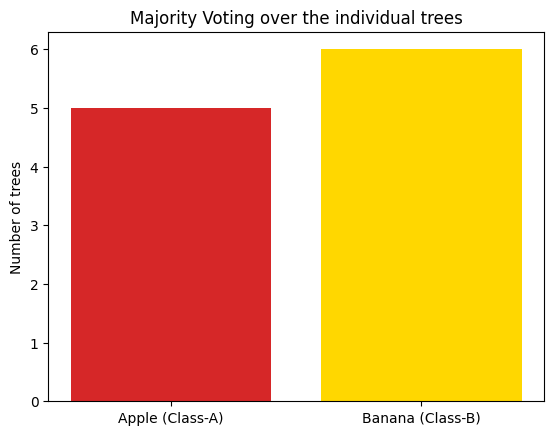

In [10]:
vote_count = Counter(votes)
print('Votes :', {names[k]: v for k, v in vote_count.items()})

final_class = vote_count.most_common(1)[0][0]
print('\nFinal class by majority voting :', names[final_class])

plt.bar([names[0], names[1]], [vote_count.get(0, 0), vote_count.get(1, 0)], color=['tab:red', 'gold'])
plt.title('Majority Voting over the individual trees')
plt.ylabel('Number of trees')
plt.show()

### Reproducing the Scenario in the Exercise Figure

In the figure, Tree-1 and Tree-2 output Class-A (Apple) and Tree-n outputs Class-B (Banana). With the same voting rule, we can compute the final class directly.

In [11]:
figure_votes = ['Apple', 'Apple', 'Banana']   # Tree-1, Tree-2, ..., Tree-n
count = Counter(figure_votes)

print('Tree outputs   :', figure_votes)
print('Vote count     :', dict(count))
print('Final class    :', count.most_common(1)[0][0])

Tree outputs   : ['Apple', 'Apple', 'Banana']
Vote count     : {'Apple': 2, 'Banana': 1}
Final class    : Apple


### Checking the Majority Vote over the Whole Test Set

The majority vote of the *n* trees is computed for every test fruit and compared with the actual fruit.

In [12]:
all_votes = np.array([t.predict(x_test) for t in trees])        # shape (n_trees, n_test)
manual_pred = np.array([Counter(all_votes[:, j]).most_common(1)[0][0]
                        for j in range(all_votes.shape[1])])

print('Manual majority-vote accuracy :', accuracy_score(y_test, manual_pred))

single_acc = [accuracy_score(y_test, t.predict(x_test)) for t in trees]
print('Single tree accuracies        :', np.round(single_acc, 3))
print('Mean single tree accuracy     :', round(np.mean(single_acc), 3))

Manual majority-vote accuracy : 0.9
Single tree accuracies        : [0.867 0.833 0.844 0.822 0.867 0.778 0.811 0.844 0.844 0.867 0.867]
Mean single tree accuracy     : 0.84


### Fitting the Model (Random Forest Classifier)

scikit-learn performs the bootstrap sampling, tree building and voting automatically.

In [13]:
model = RandomForestClassifier(n_estimators=n_trees, criterion='entropy', random_state=0)
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

print('y_pred: ', y_pred)

y_pred:  [0 1 1 1 0 0 1 0 1 0 0 1 0 0 1 1 0 1 0 0 1 0 0 0 1 0 1 0 0 0 1 1 1 0 0 0 1
 1 0 1 0 1 1 1 0 0 0 1 0 1 1 1 0 0 1 0 0 0 1 1 0 0 1 1 0 1 1 1 1 1 0 1 0 0
 0 0 0 1 1 1 0 0 1 0 1 1 0 0 0 1]


### Evaluation Metrics

In [14]:
print('Random Forest Classifier')
conf_mat = metrics.confusion_matrix(y_test, y_pred)
print('\n Confusion Matrix : \n', conf_mat)

Accuracy_score = accuracy_score(y_test, y_pred)
print('Accuracy Score : ', Accuracy_score)
print('Accuracy in Percentage : ', int(Accuracy_score * 100), '%')

print('\n', classification_report(y_test, y_pred, target_names=['Apple', 'Banana']))

Random Forest Classifier

 Confusion Matrix : 
 [[42  2]
 [ 5 41]]
Accuracy Score :  0.9222222222222223
Accuracy in Percentage :  92 %

               precision    recall  f1-score   support

       Apple       0.89      0.95      0.92        44
      Banana       0.95      0.89      0.92        46

    accuracy                           0.92        90
   macro avg       0.92      0.92      0.92        90
weighted avg       0.92      0.92      0.92        90



[Text(0.5, 1.0, 'Random Forest Classifier')]

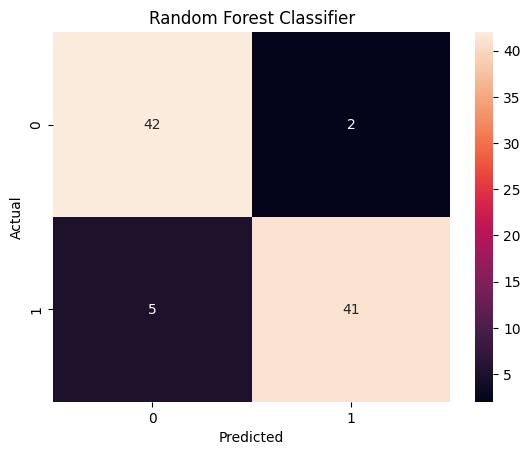

In [15]:
conf_mat = pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'])
sn.heatmap(conf_mat, annot=True).set(title='Random Forest Classifier')

### Which Fruit is Taken Most Often? (Votes of the Forest for the Test Fruits)

Final class predicted by the forest for the test fruits:
Apple     47
Banana    43
Name: count, dtype: int64

Most frequent output : Apple


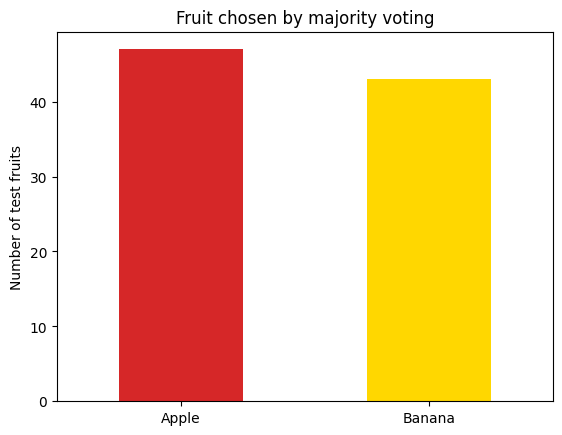

In [16]:
final_counts = pd.Series(y_pred).map({0: 'Apple', 1: 'Banana'}).value_counts()
print('Final class predicted by the forest for the test fruits:')
print(final_counts)

print('\nMost frequent output :', final_counts.idxmax())

final_counts.plot(kind='bar', color=['tab:red', 'gold'])
plt.title('Fruit chosen by majority voting')
plt.ylabel('Number of test fruits')
plt.xticks(rotation=0)
plt.show()

### Feature Importance

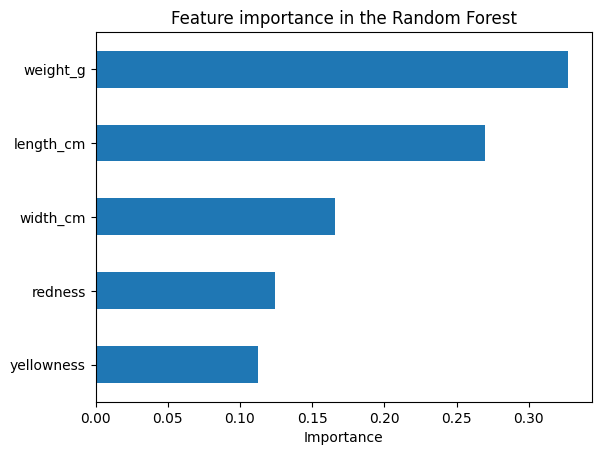

weight_g      0.327
length_cm     0.270
width_cm      0.166
redness       0.124
yellowness    0.113
dtype: float64


In [17]:
importance = pd.Series(model.feature_importances_, index=feature_cols).sort_values()
importance.plot(kind='barh')
plt.title('Feature importance in the Random Forest')
plt.xlabel('Importance')
plt.show()

print(importance.sort_values(ascending=False).round(3))

### Visualizing Tree formed (one tree of the forest)

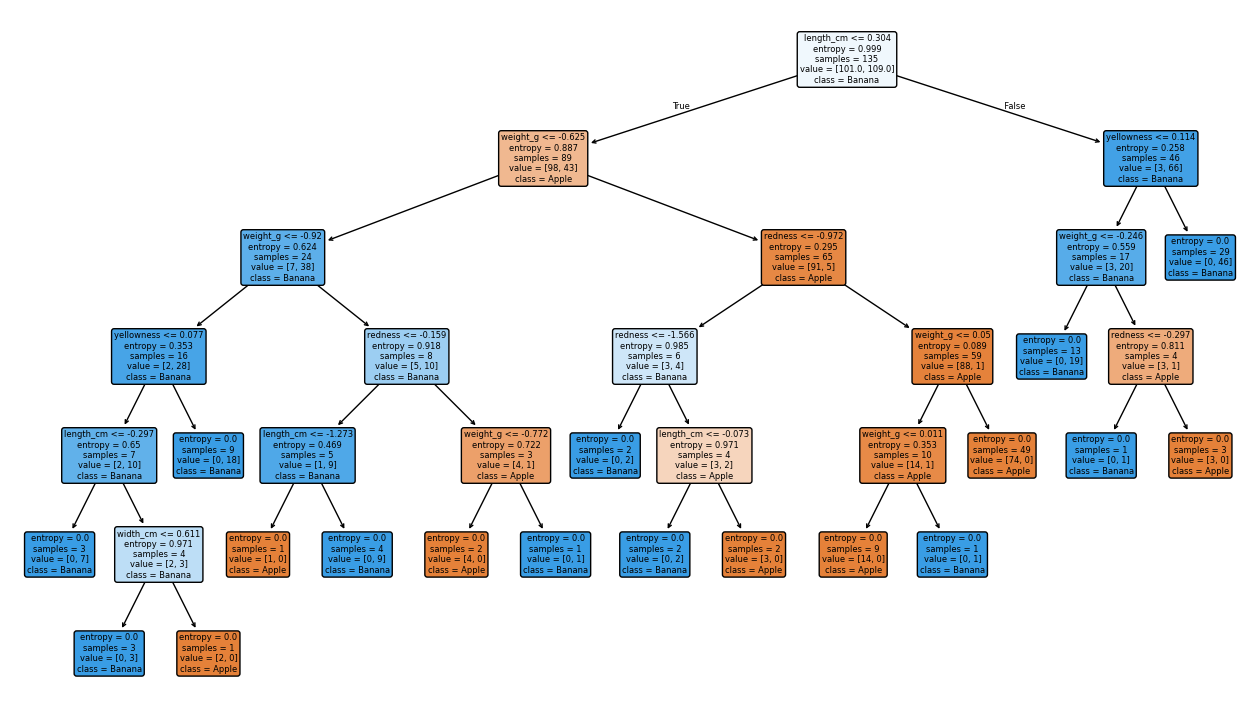

In [18]:
plt.figure(figsize=(16, 9))
tree.plot_tree(
    model.estimators_[0],
    feature_names=feature_cols,
    class_names=['Apple', 'Banana'],
    filled=True,
    rounded=True
)
plt.show()

### Interpretation

- The fruit basket is the training data. Each of the *n* trees is built from a **bootstrap sample** (random fruits drawn with replacement), and each split considers only a random subset of features, so the trees are all different.
- Every tree classifies the new fruit on its own. In the exercise figure, Tree-1 and Tree-2 say **Apple (Class-A)** and Tree-n says **Banana (Class-B)**.
- **Majority voting** counts the outputs: Apple gets 2 votes and Banana gets 1, so the final class is **Apple**. The fruit taken most often is the one that receives the most votes from the trees.
- A single tree can be wrong because it sees only one sample, but the combined vote of many trees is more stable. Compare the *Mean single tree accuracy* with the *Manual majority-vote accuracy* printed above: the vote is typically equal to or better than the average single tree, and scikit-learn's `RandomForestClassifier` does the same thing automatically.
- The test fruit used for the vote demonstration was chosen because the trees disagree on it, so it shows voting clearly. For most fruits all trees agree.
- In the synthetic basket the two classes are generated in equal numbers, so the 'most frequent output' on the test set only reflects how the data split happened to fall. The answer to the exercise question comes from the voting rule applied to the figure: **Apple**.